# HOMEWORK 8

In this homework you are going to implement your first machine learning algorithm to automatically binarize document images. The goal of document binarization is to seprate the characters (letters) from everything else. This is the crucial part for automatic document understanding and information extraction from the . In order to do so, you will use the Otsu thresholding algorithm.

At the end of this notebook, there are a couple of questions for you to answer.

In [4]:
import cv2
import math
import numpy as np
from matplotlib import pyplot as plt

def display_image(img, title="", show_axis = True):
    if isinstance(img, list):
        plt.figure()
        for idx, image in enumerate(img):
            plt.subplot(1,len(img),idx+1)
            plt.imshow(image, cmap='gray')
            plt.title(title[idx])
    else:
        plt.figure()
        plt.imshow(img, cmap='gray')
        plt.title(title)
    
    if show_axis == False:
        plt.axis('off')

plt.rcParams['figure.figsize'] = [15, 10]

Let's load the document image we will be working on in this homework.

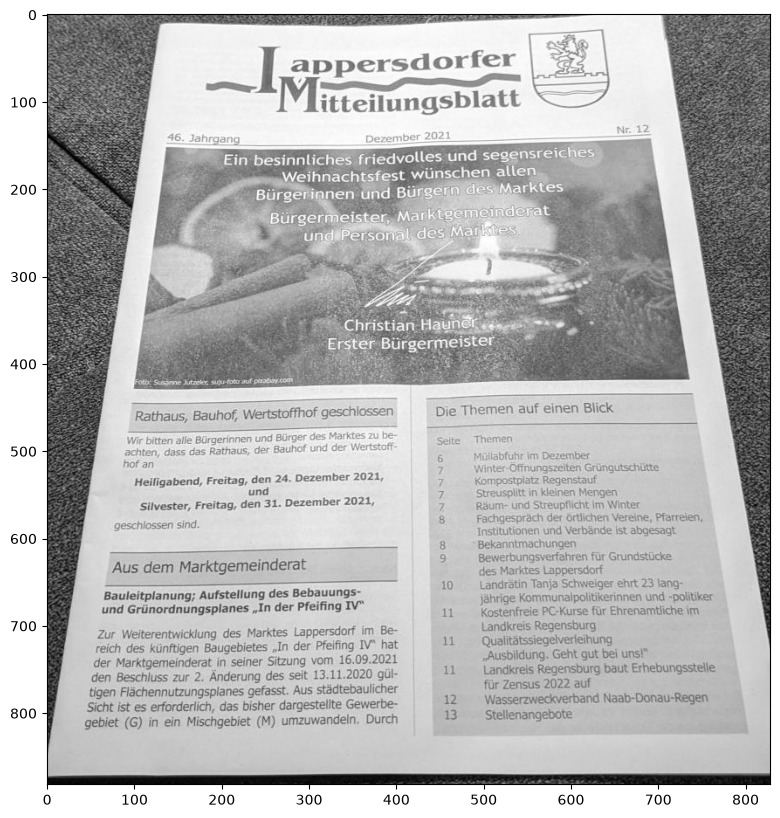

In [5]:
img = cv2.imread('../data/document.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(img, cmap='gray')

First, let's have a look at the histogram.

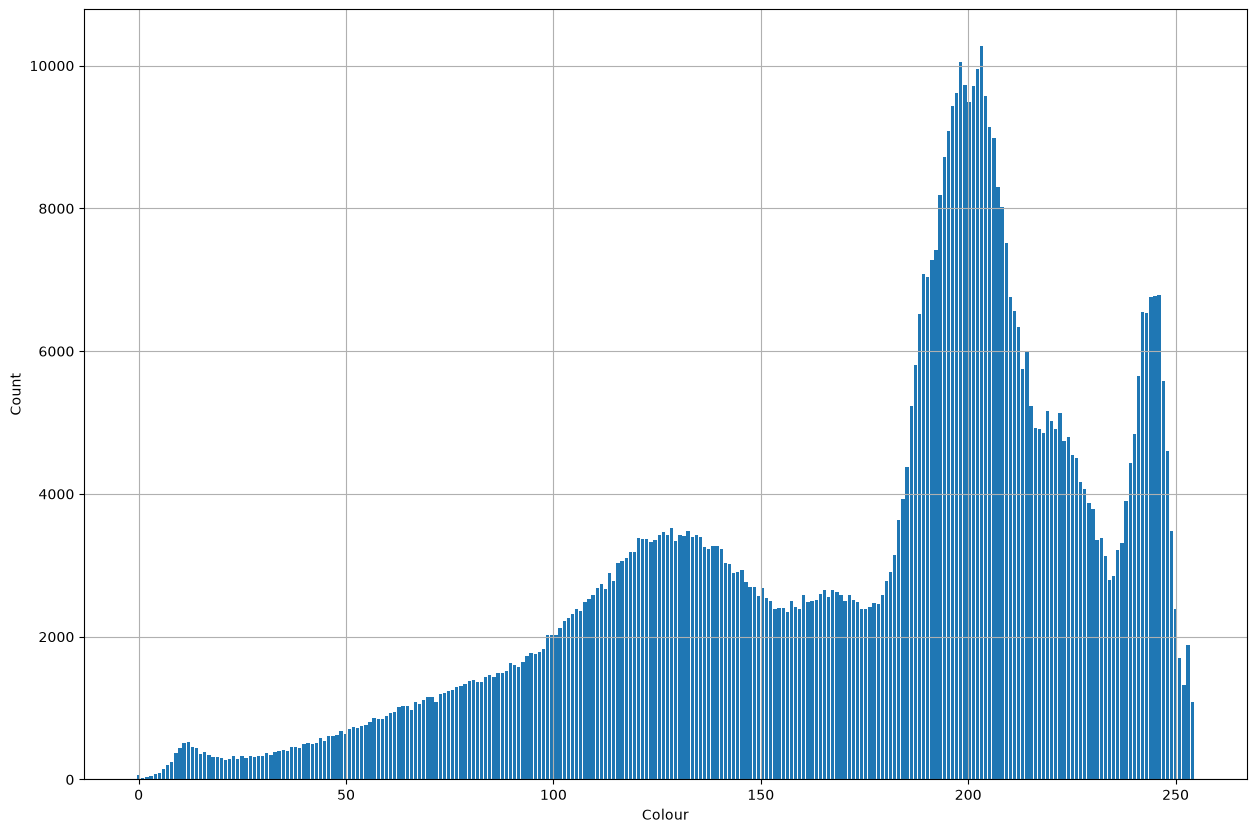

In [6]:
def plot_histogram_of_grayscale_img(img):
    h = np.histogram(img, 256)
    plt.bar(h[1][0:-1], h[0])
    plt.xlabel('Colour'), plt.ylabel('Count')
    plt.grid(True)

plot_histogram_of_grayscale_img(img)

### Otsu Thresholding

Let's now implement the Otsu thresholding algorithm. Remember that the algorithm consists of an optimization process that finds the thresholds that minimizes the intra-class variance or, equivalently, maximizes the inter-class variance.

In this homework, you are going to demonstrate the working principle of the Otsu algorithm. Therefore, you won't have to worry about an efficient implementation, we are going to use the brute force approach here.

In [7]:
def otsu_brutforce(img):
    # Get image dimensions
    rows, cols = img.shape
    # Compute the total amount of image pixels
    num_pixels = rows * cols
    
    # Initializations
    best_wcv = 1e6  # Best within-class variance (wcv)
    opt_th = None   # Threshold corresponding to the best wcv
    
    # Brute force search using all possible thresholds (levels of gray)
    for th in range(0, 256):
        # Extract the image pixels corresponding to the background
        foreground = img[img > th]
        # Extract the image pixels corresponding to the background
        background = img[img <= th]
        
        # If foreground or background are empty, continue
        if len(foreground) == 0 or len(background) == 0:
            continue
        
        # Compute class-weights (omega parameters) for foreground and background
        omega_f = len(foreground) / num_pixels
        omega_b = len(background) / num_pixels
        
        # Compute pixel variance for foreground and background
        # Hint: Check out the var function from numpy ;-)
        # https://numpy.org/doc/stable/reference/generated/numpy.var.html
        sigma2_f = np.var(foreground)
        sigma2_b = np.var(background)
        
        # Compute the within-class variance
        wcv = omega_f * sigma2_f + omega_b * sigma2_b
        
        # Perform the optimization
        if wcv < best_wcv:
            best_wcv = wcv
            opt_th = th
    return opt_th

def otsu_open_cv(img):
    ret, otsu_img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return ret, otsu_img

opt_th_brutforce = otsu_brutforce(img)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {opt_th_brutforce}")

ret, otsu_img = otsu_open_cv(img)
print(f"Optimal threshold value found by Otsu: {ret}")

Optimal threshold: 159
Optimal threshold value found by Otsu: 159.0


Finally, let's compare the original image and its thresholded representation.

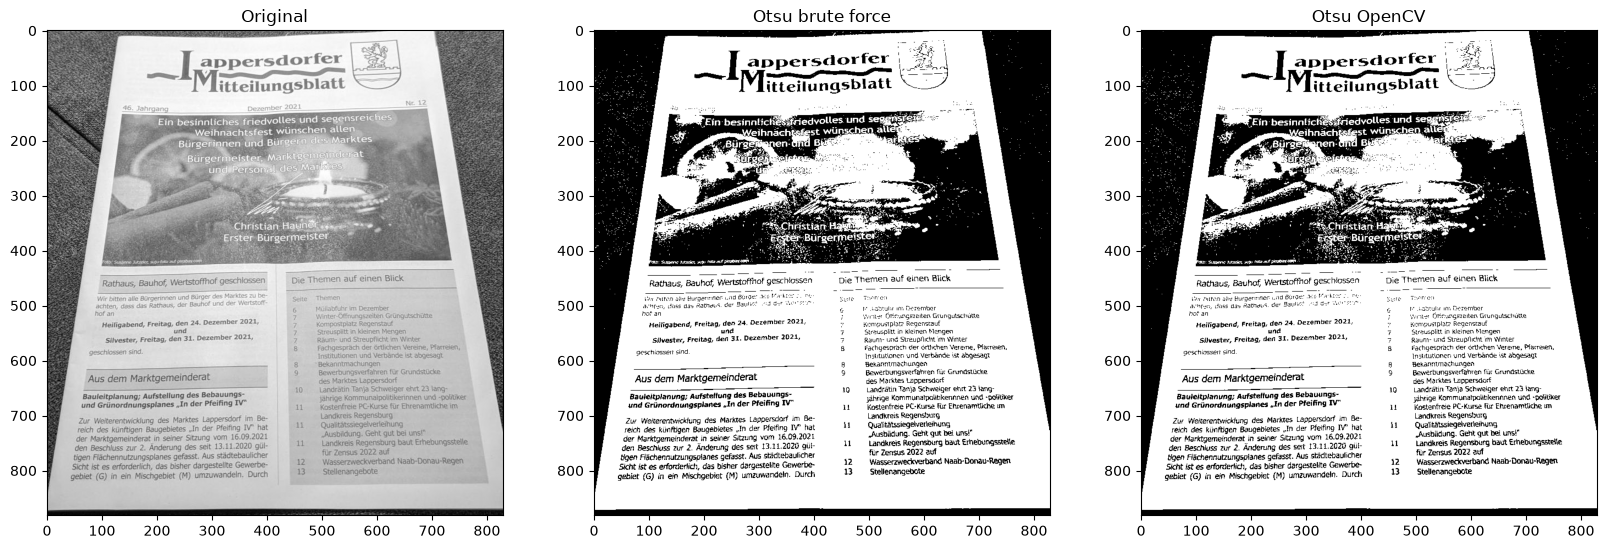

In [8]:
plt.rcParams['figure.figsize'] = [20, 15]
display_image([img, img > opt_th_brutforce, otsu_img], ["Original", "Otsu brute force", "Otsu OpenCV"])

### Additional work on image just for the testing purposes for myself to answer questions
* Question 1 

Optimal threshold: 159


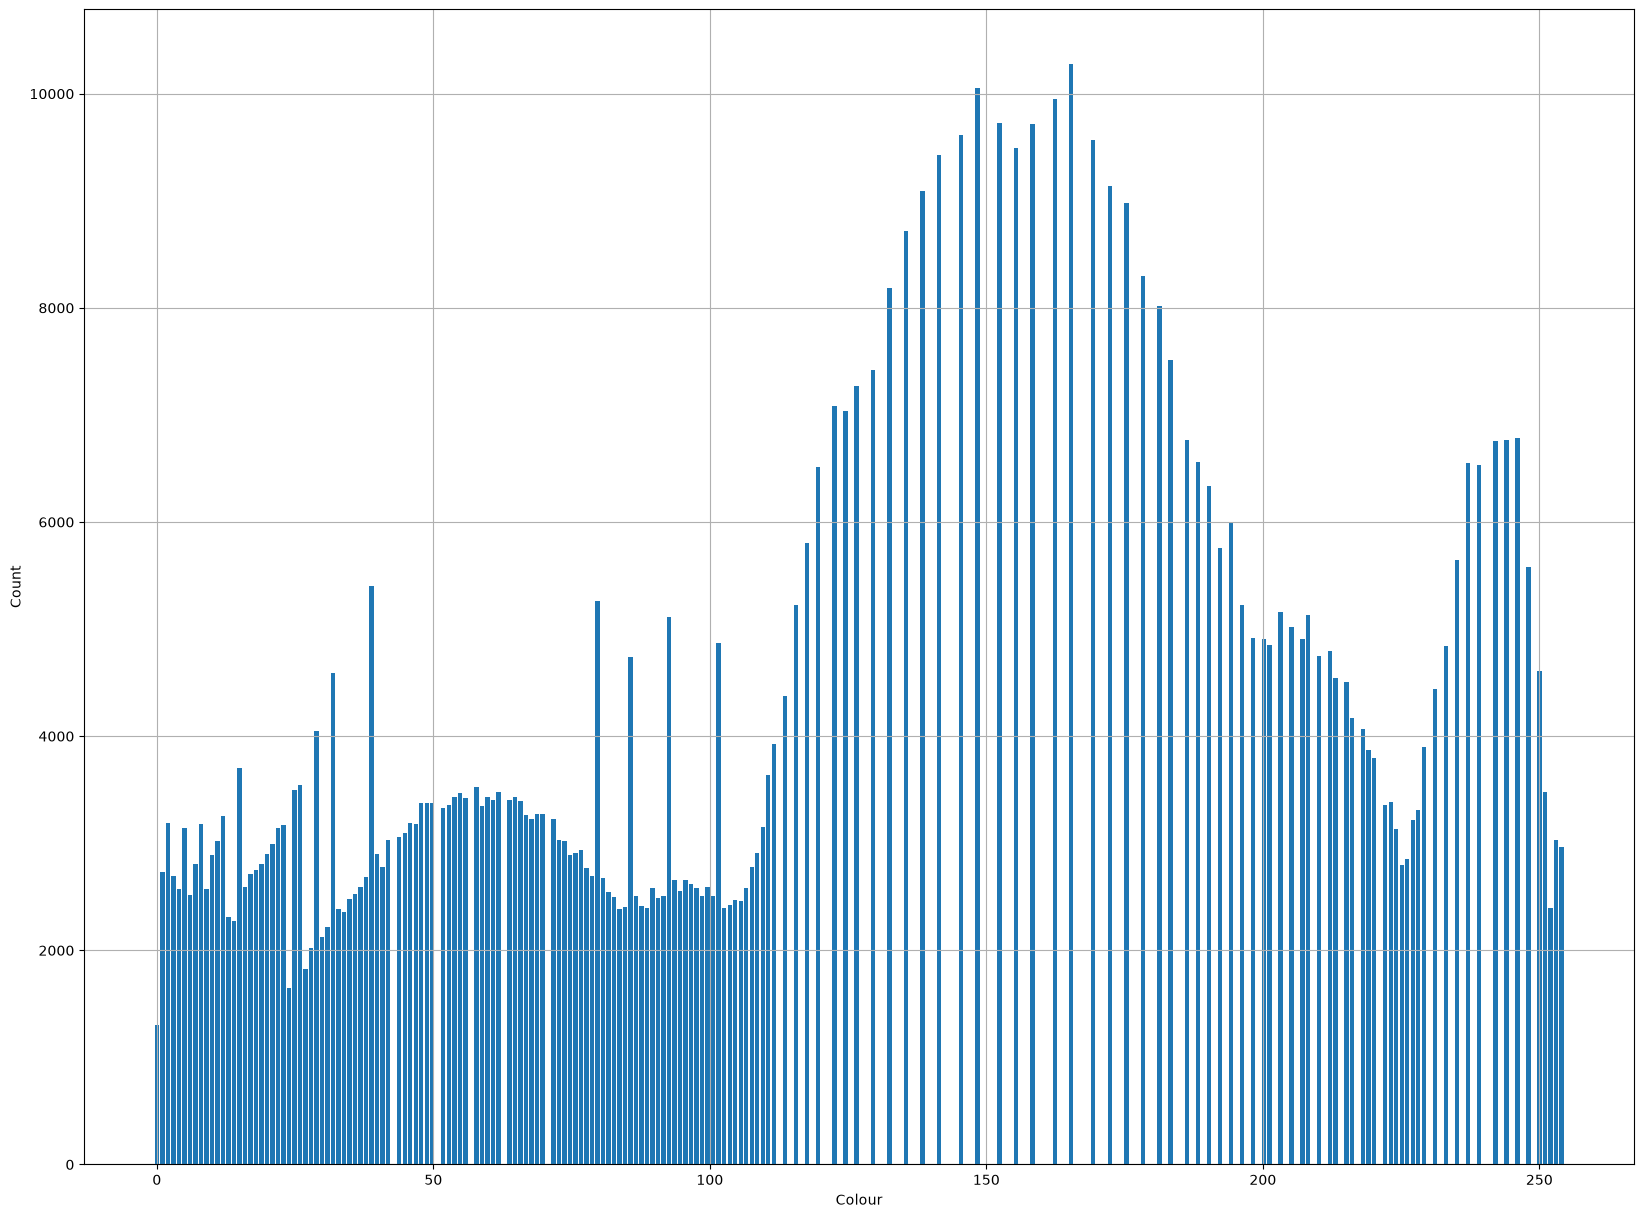

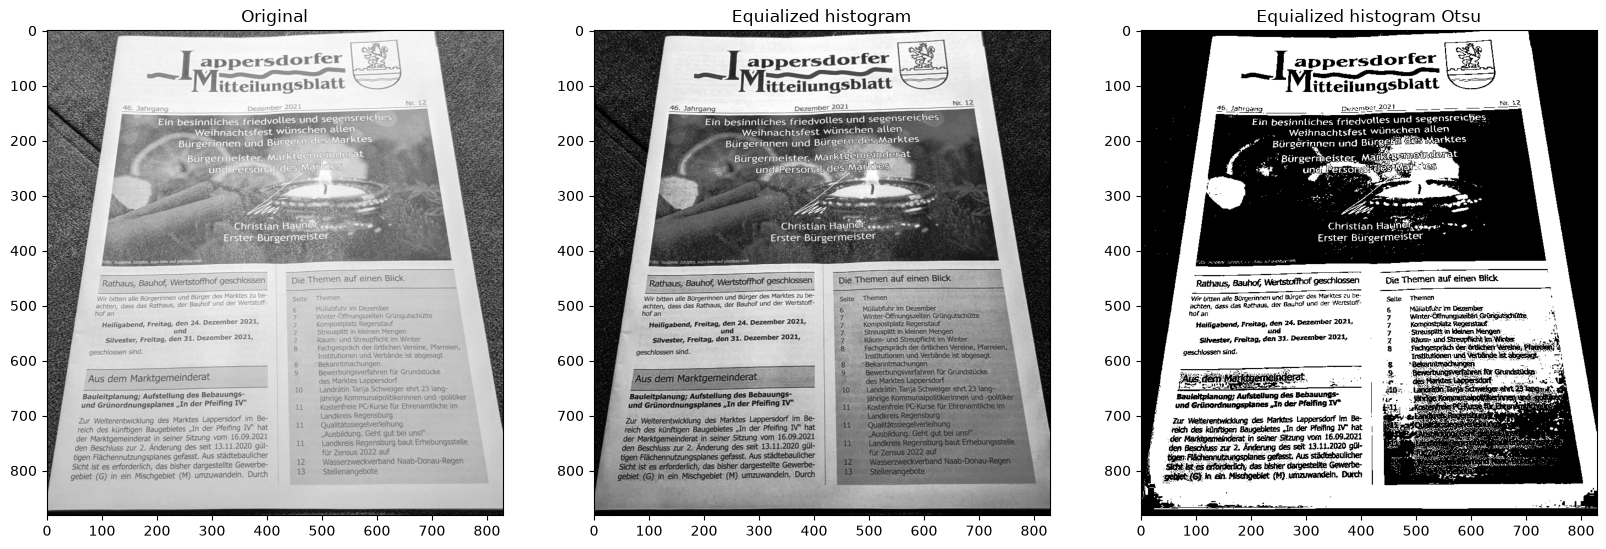

In [9]:
# lets look at equalized histogram, display it and take a look at image after equalization
equalized_img = cv2.equalizeHist(img)
plot_histogram_of_grayscale_img(equalized_img)
opt_th_brutforce_eaualized = otsu_brutforce(equalized_img)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {opt_th_brutforce}")
display_image([img, equalized_img, equalized_img > opt_th_brutforce_eaualized], ["Original", "Equialized histogram", "Equialized histogram Otsu"])
# now lets find the new optimal threshold and see the result

* Question 2

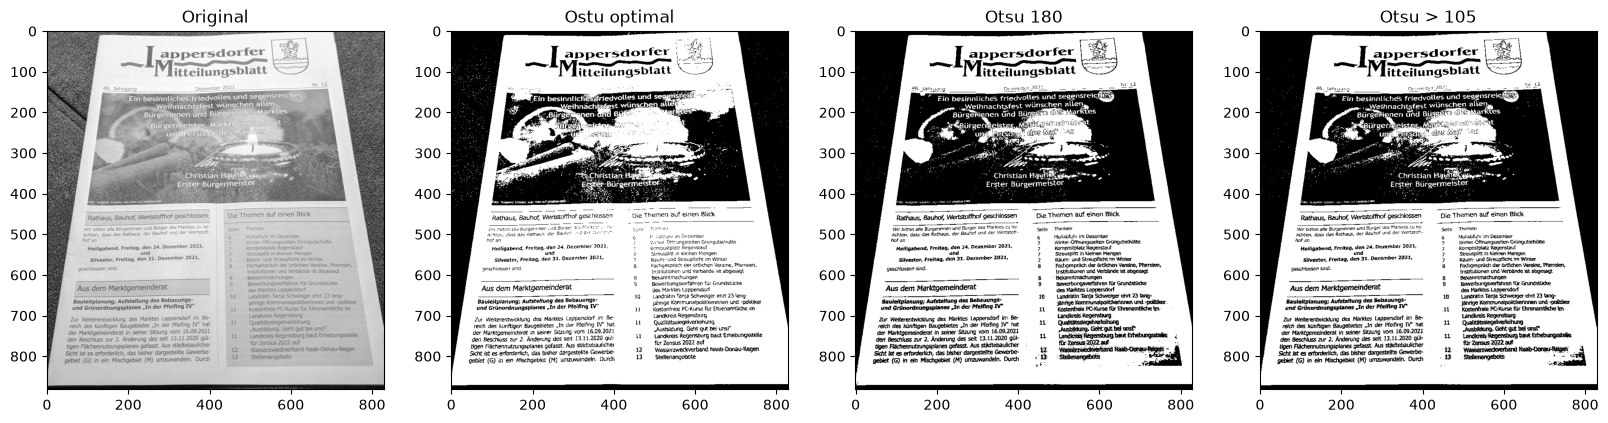

In [10]:
display_image([img, img > opt_th_brutforce, img > 180, equalized_img > 105], ["Original", "Ostu optimal", "Otsu 180", "Otsu > 105"])

* Question 3

Optimal threshold: 174
Optimal threshold: 140
Optimal threshold: 145


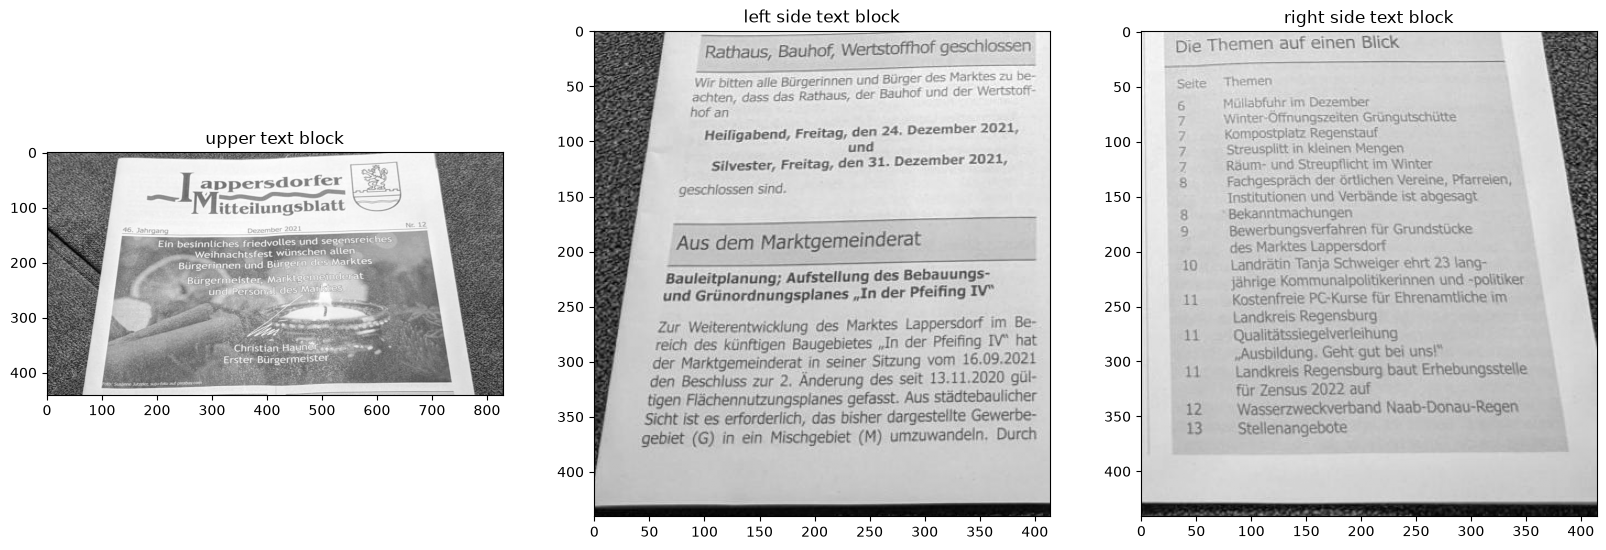

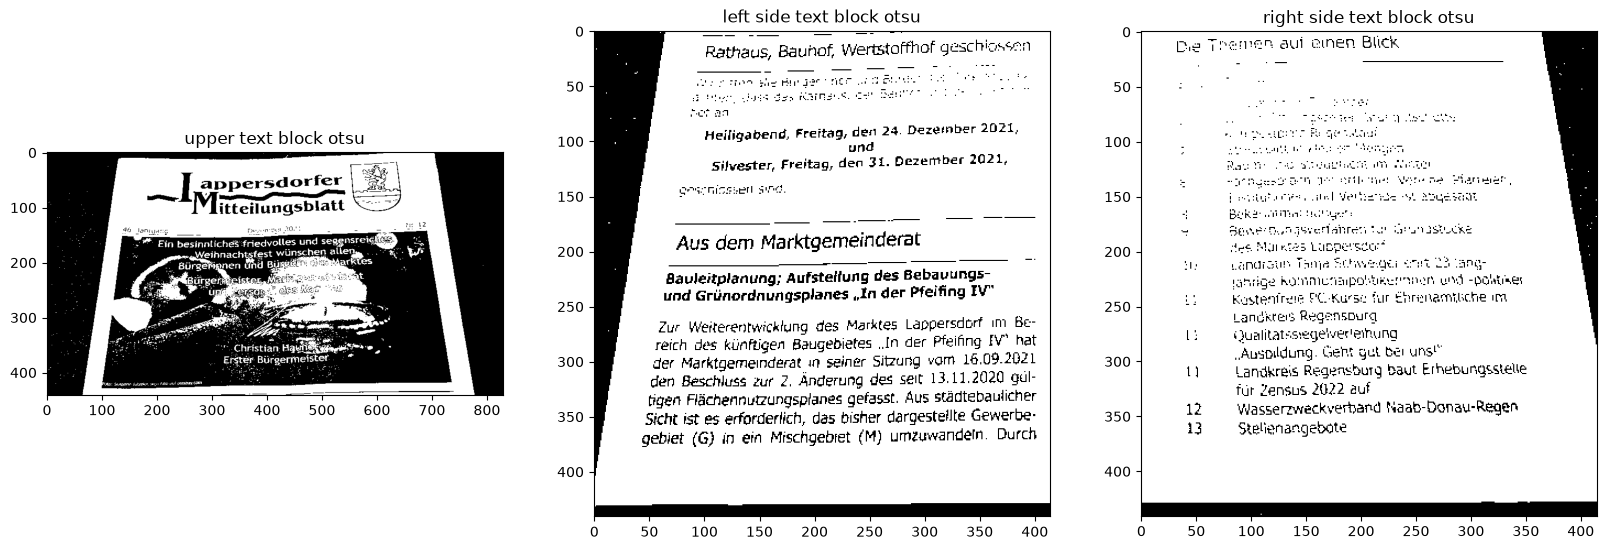

In [14]:
rows, cols = img.shape

upper_text_block = img[0:rows//2]
left_side_block = img[rows//2:rows, 0:cols//2]
right_side_block = img[rows//2:rows, cols//2:cols]
display_image([upper_text_block, left_side_block, right_side_block], ["upper text block", "left side text block", "right side text block"])

upper_text_block_opt_th_brutforce = otsu_brutforce(upper_text_block)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {upper_text_block_opt_th_brutforce}")
right_side_block_opt_th_brutforce = otsu_brutforce(right_side_block)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {right_side_block_opt_th_brutforce}")
left_side_block_opt_th_brutforce = otsu_brutforce(left_side_block)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {left_side_block_opt_th_brutforce}")

display_image([upper_text_block > upper_text_block_opt_th_brutforce, left_side_block > left_side_block_opt_th_brutforce, right_side_block > right_side_block_opt_th_brutforce], ["upper text block otsu", "left side text block otsu", "right side text block otsu"])

The result is not as good as I expected :(

Optimal threshold: 127
Optimal threshold: 127
Optimal threshold: 126


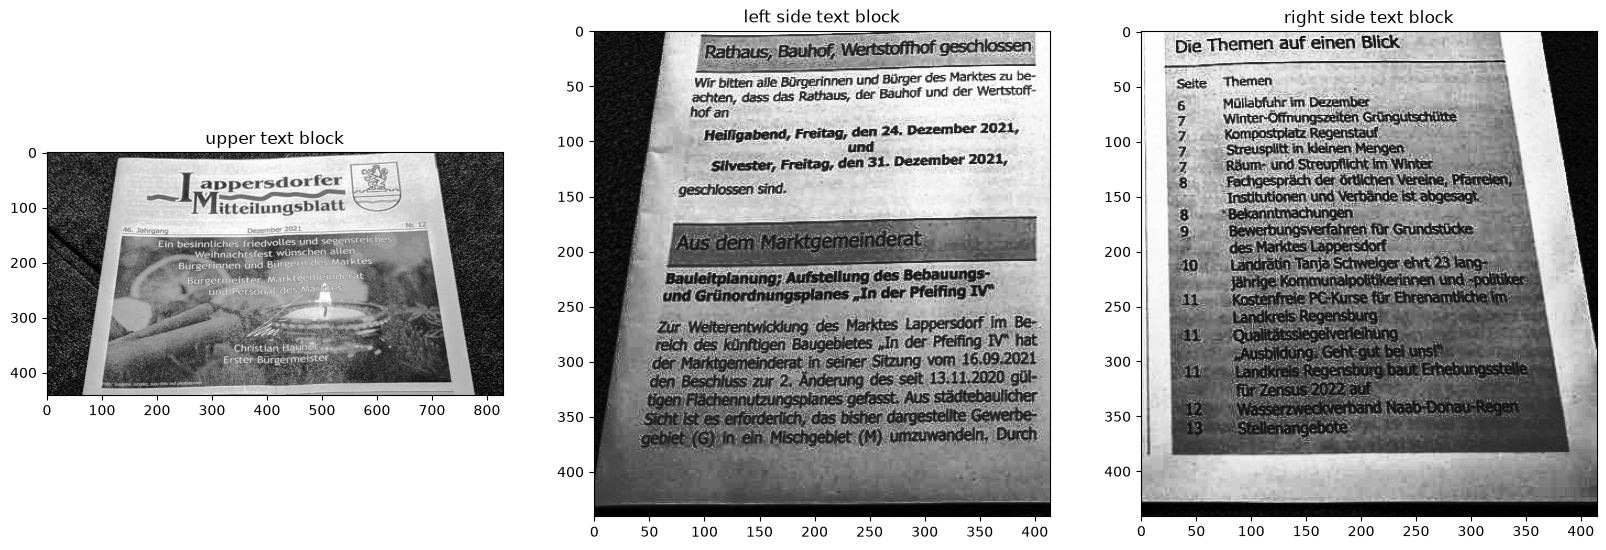

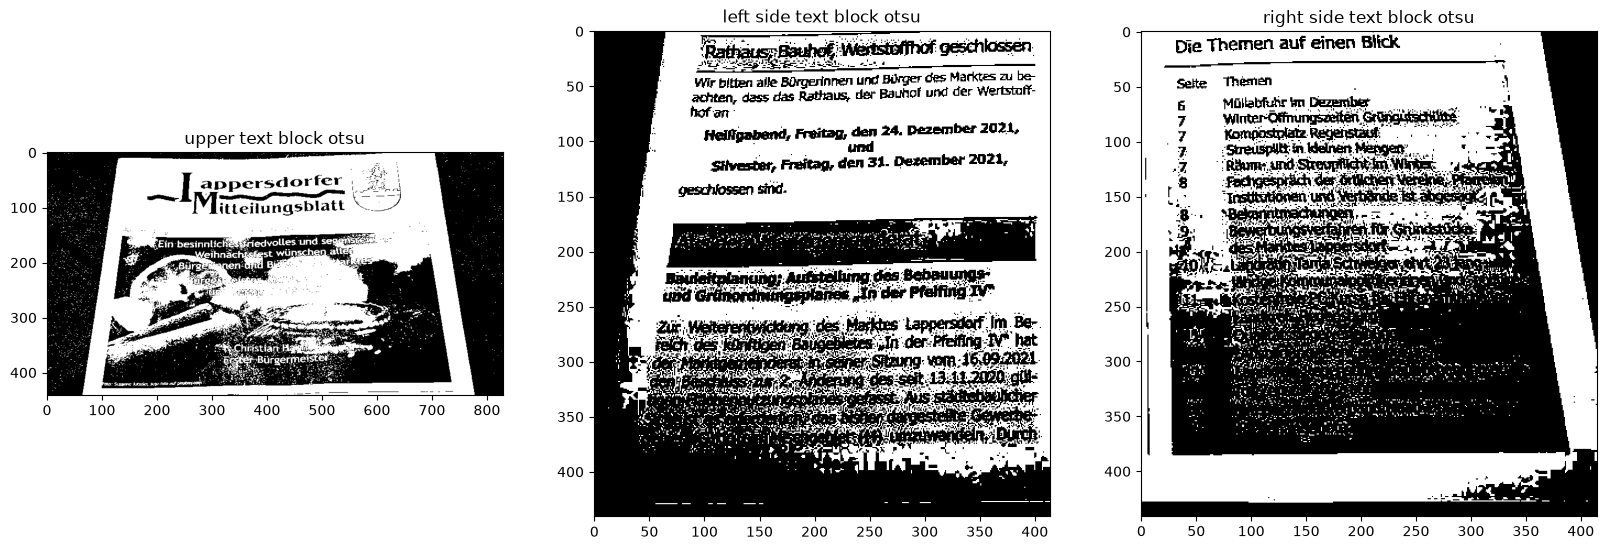

In [15]:
upper_text_block = cv2.equalizeHist(upper_text_block)
left_side_block = cv2.equalizeHist(left_side_block)
right_side_block = cv2.equalizeHist(right_side_block)
display_image([upper_text_block, left_side_block, right_side_block], ["upper text block", "left side text block", "right side text block"])

upper_text_block_opt_th_brutforce = otsu_brutforce(upper_text_block)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {upper_text_block_opt_th_brutforce}")
right_side_block_opt_th_brutforce = otsu_brutforce(right_side_block)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {right_side_block_opt_th_brutforce}")
left_side_block_opt_th_brutforce = otsu_brutforce(left_side_block)
# Print out the optimal threshold found by Otsu algorithm
print(f"Optimal threshold: {left_side_block_opt_th_brutforce}")

display_image([upper_text_block > upper_text_block_opt_th_brutforce, left_side_block > left_side_block_opt_th_brutforce, right_side_block > right_side_block_opt_th_brutforce], ["upper text block otsu", "left side text block otsu", "right side text block otsu"])

### Questions

* Looking at the computed histogram, could it be considered bimodal?

  A: The histogram shows that the image has 3 peaks that we can distinguish:
  One broad region and two peaks, so considering this observation we can't state that the image is bimodal in our case. We have a white text that has a preety close in color background that leads to the text being not readable at all in two color image.
  As well in this case we have white text, black text on white background and black text on gray background.
  As you can see I've tried to check what result we can achieve with histogram equalization, but we can see now some noise added and threshold does not fulfill our purpose, we have issues regarding text on grey background as well some moise on the text on white background.

    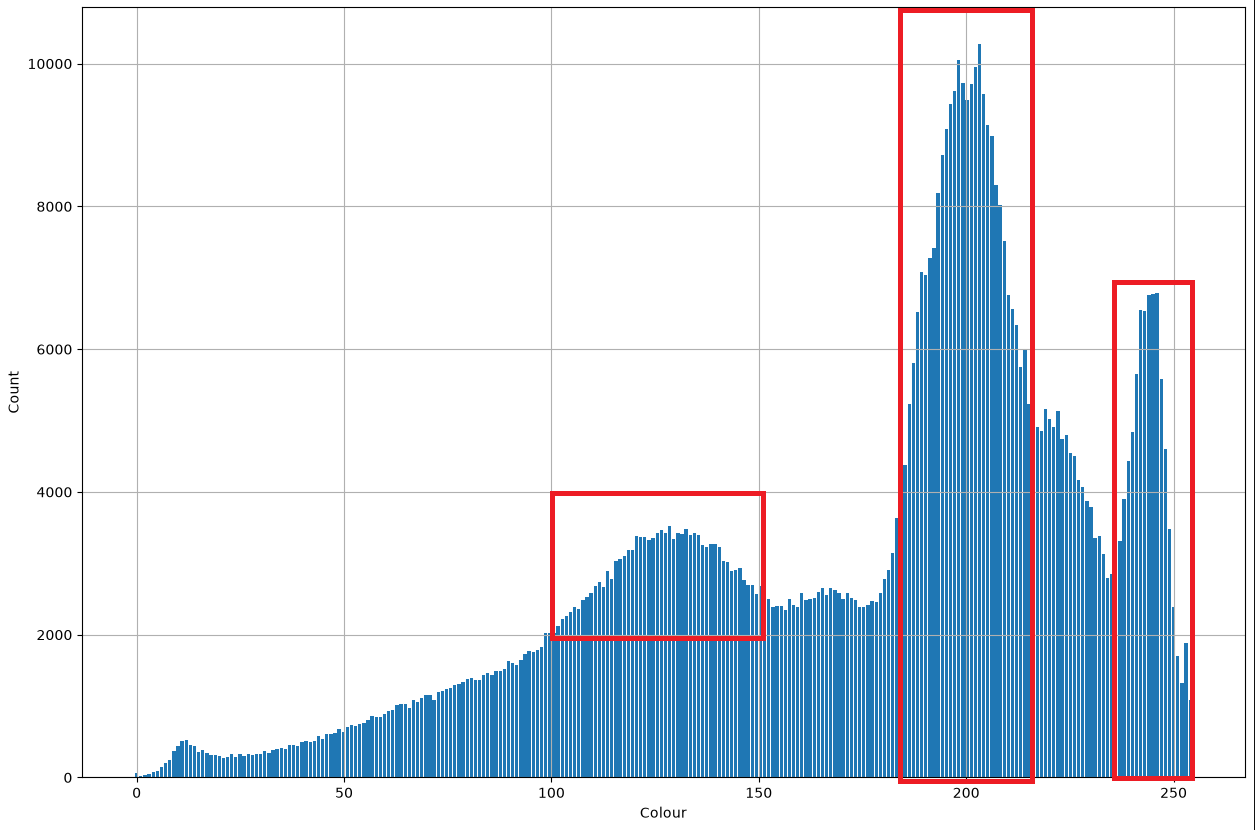


* Looking at the computed histogram, what binarization threshold would you chose? Why?

  A: Looking at the histogram and resulting image I would take a value closer to the second peak region to eliminate some noise that makes the white text unreadable and eliminate wide region pixels it will make the text more readable especially the text on white background.
* Looking at the resulting (thresholded) image, is the text binarization (detection) good?

  After analysis of the resulting image I can say that the result could be improved sice we have not a bimodal image it will not be easy to satisfy by one theshold old regions on the image, as a suggestion the image could be splitted in different blocks - upper wgite text on image, the block under image in the left side and the block of text on the right side under image, maybe processing those images separatelly will give better results and bring less noise and more readable text overall. As a second thought as in previous homework we applied homography to the document image and cut off the background that brings some color noise to the document, so we will eliminate the background and make the image more clear.

  Update: I can say that splitting image does not bring desired results and equalization of histogram as well, maybe changing the threshold can bring more better results.